# 1 · Can the record tell the whole story?

Picking the team with the better record is a sensible place to start. But a 20–10 team can arrive at that record in different ways: comfortable wins, close finishes, a stable rotation, or a recent stretch that looks different from its season. I want to know whether the supplied team and player histories contain useful detail beyond that simple choice.

The product is **a pregame probability that the home team wins**, not just a winner label. This notebook explores what the files can support and develops the basketball reasons for looking at each candidate signal. The next notebook turns those ideas into information available before a specific tipoff; the third compares models; the fourth checks the predictions against outcomes.

**Scope:** basketball exploration uses development seasons 2014–15 through 2022–23. We inspect 2023–24's coverage, but its outcomes do not drive the exploratory choices below. These notebooks expand the explanation of a previously frozen model. The newly requested better-record comparison is identified as retrospective in the evaluation notebook.

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd() if (Path.cwd() / "Data").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.charts import feature_label

TABLES = ROOT / "artifacts/tables"
FIGURES = ROOT / "artifacts/figures"
CLAY, TEAL = "#b55832", "#427b83"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.figsize": (9, 4),
        "axes.grid": False,
        "font.size": 10,
    }
)
pd.set_option("display.max_columns", 14)


def finish(fig, filename=None):
    fig.tight_layout()
    if filename:
        fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    plt.show()

## First, what counts as a game?

The team file is written from the offense's perspective. A game therefore appears twice: once for each team. The player file has a different unit—one rostered player in one game—and includes people who did not play. I need to establish those units before choosing joins or interpreting a missing appearance.

In [2]:
from src.data import load_data, validate_data

team, player = load_data()
games, audit, contradictions, mismatches = validate_data(team, player)
dimensions = pd.DataFrame(
    {
        "rows": [len(team), len(player)],
        "columns": [len(team.columns), len(player.columns)],
        "unique games": [team.nbagameid.nunique(), player.nbagameid.nunique()],
    },
    index=["Team", "Player"],
)
display(dimensions)
example_id = int(
    team.loc[(team.season == 2018) & (team.gametype == 2), "nbagameid"].iloc[0]
)
display(
    team.loc[
        team.nbagameid.eq(example_id),
        [
            "nbagameid",
            "gamedate",
            "off_team",
            "def_team",
            "off_home",
            "off_win",
            "points",
            "possessions",
        ],
    ]
)
display(
    player.loc[
        player.nbagameid.eq(example_id),
        ["team", "player_name", "starter", "missed", "seconds", "points"],
    ].head(12)
)

,rows,columns,unique games
Team,27144,41,13572
Player,434797,59,13572


,nbagameid,gamedate,off_team,def_team,off_home,off_win,points,possessions
486,21800965,2019-03-06,MIA,CHA,0,1,91,93
541,21800965,2019-03-06,CHA,MIA,1,0,84,94


,team,player_name,starter,missed,seconds,points
389534,CHA,Miles Bridges,1,0,1096.8,3
389535,CHA,Malik Monk,0,0,0.0,0
389536,CHA,Marvin Williams,1,0,2117.6,9
389537,CHA,Jeremy Lamb,0,0,1651.6,7
389538,CHA,Devonte Graham,0,0,0.0,0
389539,CHA,Nicolas Batum,1,0,2362.0,9
389540,CHA,Shelvin Mack,0,0,0.0,0
389541,CHA,Dwayne Bacon,0,0,0.0,0
389542,CHA,Bismack Biyombo,0,0,472.0,4
389543,CHA,Tony Parker,0,0,1301.6,2


The two team rows contain the same contest, not two independent training examples. I pair them and keep the designated-home perspective. Player on-court team totals overlap across players, so adding those totals would count the same possessions repeatedly. Individual minutes, points and shot attempts can be aggregated for different purposes, but the distinction matters.

## What needs cleaning, and what should be preserved?

A tidy file can still contain awkward basketball records. I check identifiers, shooting arithmetic, outcome consistency, the opponent join and whether player points reconcile to team points. I also inspect clocks and participation flags because player weighting depends on them.

In [3]:
quality = pd.Series(
    {
        "Duplicate game-team keys": team.duplicated(["nbagameid", "off_team"]).sum(),
        "Duplicate game-player keys": player.duplicated(
            ["nbagameid", "nbapersonid"]
        ).sum(),
        "Missing player names": player.player_name.isna().sum(),
        "Player/team point mismatches": len(mismatches),
        "Missed flag but positive seconds": len(contradictions),
        "Points with zero seconds": audit["zero_seconds_with_points"],
        "Team games below 239 player-minutes": audit["team_games_below_239_minutes"],
    },
    name="Count",
)
display(quality.to_frame())
display(contradictions[["nbagameid", "player_name", "missed", "seconds"]])

,Count
Duplicate game-team keys,0
Duplicate game-player keys,0
Missing player names,4
Player/team point mismatches,0
Missed flag but positive seconds,4
Points with zero seconds,2
Team games below 239 player-minutes,34


,nbagameid,player_name,missed,seconds
56613,40500131,Ira Newble,1,0.3
85873,40400126,Justin Reed,1,0.5
116126,41000162,Armon Johnson,1,0.3
246142,22000158,R.J. Hampton,1,3.3


There are no duplicate keys or point-reconciliation failures. Four missing names retain usable player IDs. Four `missed=1` records have positive seconds: for historical participation summaries, playing takes precedence. Two players have points but zero recorded seconds, so I preserve their scoring rather than deleting entire games.

The low clock totals are more consequential for a proposed pace measure. I cannot repair the source clock from these files. I therefore use recorded minute **shares** and omit clock-derived pace. Cleaning here means making explicit decisions, not forcing every record to look ideal.

## How much basketball is actually covered?

Regular seasons provide far more examples than playoff series. They also support a natural evaluation: fit earlier seasons, then forecast later ones. Requiring ten earlier games per team gives within-season records and roles time to develop; the cost is losing opening games from prediction coverage.

,season,games,eligible,excluded_openers
0,2014,1230,1072,158
1,2015,1230,1073,157
2,2016,1230,1074,156
3,2017,1230,1075,155
4,2018,1230,1074,156
5,2019,1059,906,153
6,2020,1080,924,156
7,2021,1230,1073,157
8,2022,1230,1073,157
9,2023,1230,1074,156


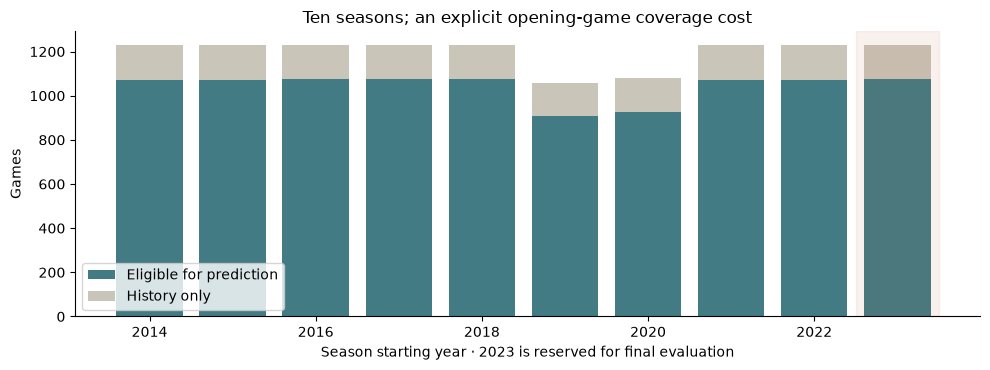

In [4]:
coverage = pd.read_csv(TABLES / "coverage.csv")
coverage["excluded_openers"] = coverage.games - coverage.eligible
display(coverage[["season", "games", "eligible", "excluded_openers"]])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(coverage.season, coverage.eligible, color=TEAL, label="Eligible for prediction")
ax.bar(
    coverage.season,
    coverage.excluded_openers,
    bottom=coverage.eligible,
    color="#c9c5b9",
    label="History only",
)
ax.axvspan(2022.5, 2023.5, color=CLAY, alpha=0.08)
ax.set(
    xlabel="Season starting year · 2023 is reserved for final evaluation",
    ylabel="Games",
    title="Ten seasons; an explicit opening-game coverage cost",
)
ax.legend(loc="lower left")
finish(fig, "story_coverage.png")

The source contains 11,979 regular-season games and 10,418 eligible matchups. The two shorter seasons remain in the analysis with their actual counts; I do not invent missing games or demand 82 from every team. The 2023–24 test covers 1,074 of 1,230 games. That denominator will stay the same for every final comparison.

## Start with the simplest basketball advantage: playing at home

Before adding team strength, I want to know how often a constant home pick would succeed. A historical home-win rate also supplies the simplest probability forecast: the same number for every game, estimated only from earlier training data.

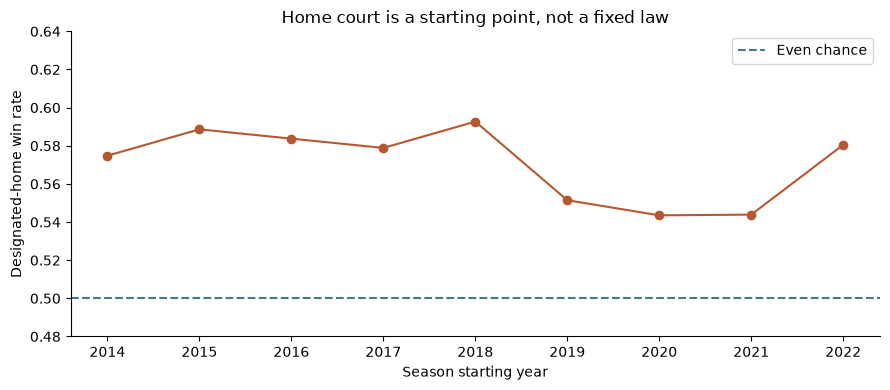

,win_rate,games
season,,
2014,0.575,1230
2015,0.589,1230
2016,0.584,1230
2017,0.579,1230
2018,0.593,1230
2019,0.551,1059
2020,0.544,1080
2021,0.544,1230
2022,0.580,1230


Across development games: 57.2%


In [5]:
regular = games[(games.gametype == 2) & (games.season < 2023)]
hosts = regular[regular.off_home.eq(1)]
home = hosts.groupby("season").agg(
    win_rate=("off_win", "mean"), games=("off_win", "size")
)
fig, ax = plt.subplots()
ax.plot(home.index, home.win_rate, marker="o", color=CLAY)
ax.axhline(0.5, color=TEAL, linestyle="--", label="Even chance")
ax.set(
    xlabel="Season starting year",
    ylabel="Designated-home win rate",
    title="Home court is a starting point, not a fixed law",
    ylim=(0.48, 0.64),
)
ax.legend()
finish(fig, "story_home_court.png")
display(home.round(3))
print(f"Across development games: {hosts.off_win.mean():.1%}")

The designated home team wins 57.2% overall, but the rate varies. The files do not identify neutral sites, so I call this a **designated-home** effect and avoid a causal arena claim. In the matchup model, home orientation and the intercept carry this baseline tendency. The later test will reveal whether the historical rate still fits.

## Is record mostly a summary of how well a team scores and defends?

Winning percentage is intuitive, but it treats a one-point win and a twenty-point win alike. Net rating asks how many points a team outscores its opponents by per 100 possessions. I first look at complete development team-seasons to understand the basketball relationship; these end-of-season summaries are descriptive and will never be used to predict earlier games.

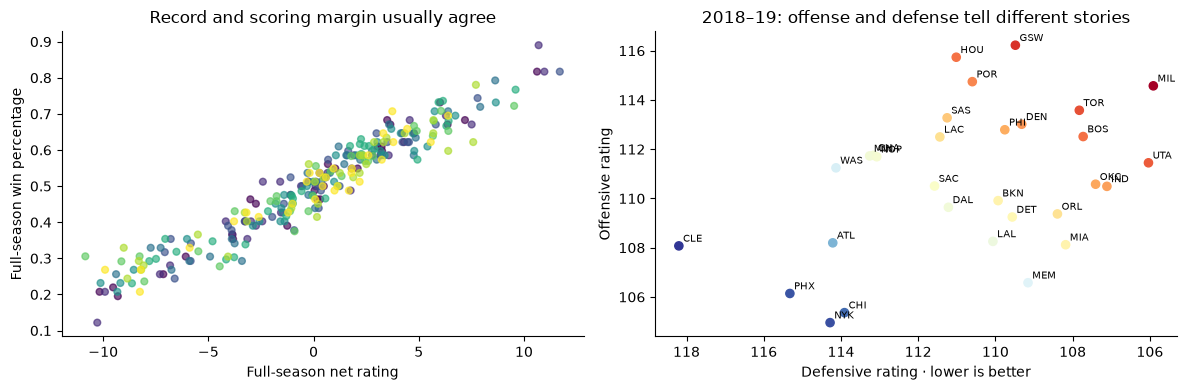

Team-season net-rating/record correlation: 0.963


In [6]:
seasons = pd.read_csv(TABLES / "eda_team_seasons.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(
    seasons.net_rating,
    seasons.win_pct,
    c=seasons.season,
    cmap="viridis",
    alpha=0.65,
    s=24,
)
axes[0].set(
    xlabel="Full-season net rating",
    ylabel="Full-season win percentage",
    title="Record and scoring margin usually agree",
)
sample = seasons[seasons.season.eq(2018)]
axes[1].scatter(sample.drtg, sample.ortg, c=sample.net_rating, cmap="RdYlBu_r", s=35)
for row in sample.itertuples():
    axes[1].annotate(
        row.off_team,
        (row.drtg, row.ortg),
        fontsize=7,
        xytext=(3, 3),
        textcoords="offset points",
    )
axes[1].invert_xaxis()
axes[1].set(
    xlabel="Defensive rating · lower is better",
    ylabel="Offensive rating",
    title="2018–19: offense and defense tell different stories",
)
finish(fig, "story_strength.png")
print(
    "Team-season net-rating/record correlation:",
    round(seasons.net_rating.corr(seasons.win_pct), 3),
)

The relationship makes record a serious baseline, not a straw man. It also motivates net rating as a compact second view of strength. Offense and defense are worth exploring separately, but entering offense, defense and their exact difference together would introduce mechanical redundancy.

The forecasting question is stricter than the full-season picture: does **strength measured before a game** track that game's outcome?

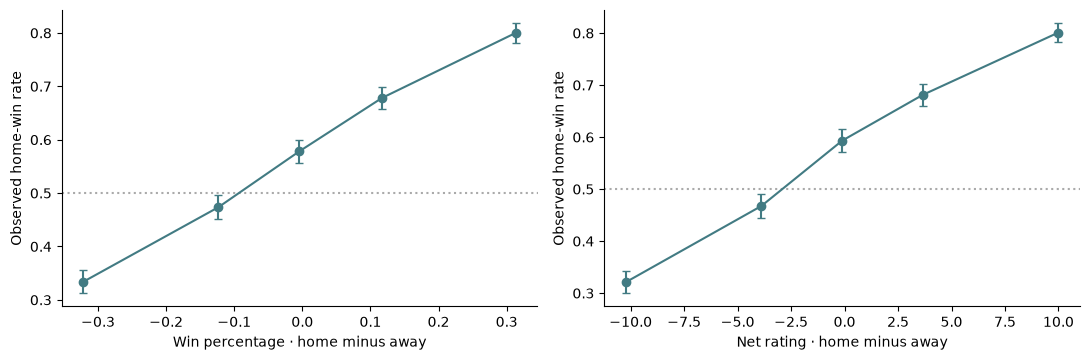

,bin,value,home_win_rate,n
0,"(-0.77, -0.194]",-0.321617,0.333868,1869
1,"(-0.194, -0.0566]",-0.123291,0.473515,1869
2,"(-0.0566, 0.0494]",-0.004517,0.578158,1868
3,"(0.0494, 0.189]",0.116976,0.678247,1871
4,"(0.189, 0.846]",0.313511,0.800214,1867


In [7]:
from src.analysis import binned_outcomes

matchups = pd.read_csv(TABLES / "matchups.csv.gz", parse_dates=["gamedate"])
dev = matchups[matchups.eligible & matchups.season.lt(2023)].copy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for ax, feature in zip(axes, ["win_pct_diff", "net_rating_diff"]):
    b = binned_outcomes(dev, feature)
    ax.errorbar(
        b.value,
        b.home_win_rate,
        yerr=[b.home_win_rate - b.lower, b.upper - b.home_win_rate],
        fmt="o-",
        color=TEAL,
        capsize=3,
    )
    ax.axhline(0.5, color="#aaa", linestyle=":")
    ax.set(
        xlabel=feature_label(feature) + " · home minus away",
        ylabel="Observed home-win rate",
    )
finish(fig, "story_pregame_strength.png")
display(binned_outcomes(dev, "win_pct_diff")[["bin", "value", "home_win_rate", "n"]])

The pregame relationship is in the expected direction too. Each point groups roughly one fifth of development games; the counts make clear this is not a handful of selected matchups. The intervals are descriptive Wilson intervals that treat games as independent. Overlapping team histories and schedule dependence mean they should not be read as a definitive significance test.

**Modeling consequence:** keep a parameter-free better-record winner rule, a fitted win-percentage probability model, and a fitted net-rating model as distinct comparisons. A winner rule cannot say whether its favorite has a 51% or 90% chance.

## What basketball detail could net rating be hiding?

I next look at shooting, turnovers and second chances. They are plausible descriptions of *how* a team creates an advantage. Plausibility does not establish incremental prediction value: good shooting also contributes directly to net rating, and team strength can confound every univariate relationship here.

,label,question,construction,caution
2,Effective field goal percentage,Does the team's shot-making profile add detail?,(Prior FG made + 0.5 × threes made) / FG attem...,Shooting fluctuates; strong overlap with net r...
3,Opponent shooting efficiency,Has the defense been limiting efficient shots?,Opponent version of effective FG percentage,Does not separate shot quality from opponent s...
4,Turnover rate,Is the offense losing scoring chances?,Prior turnovers / (shot attempts + turnovers),A conditional coefficient is not a causal effe...
5,Offensive rebounding,Does the offense create second chances?,Offensive rebounds / offensive rebound chances,Team rebounds and opponent rows need correct i...


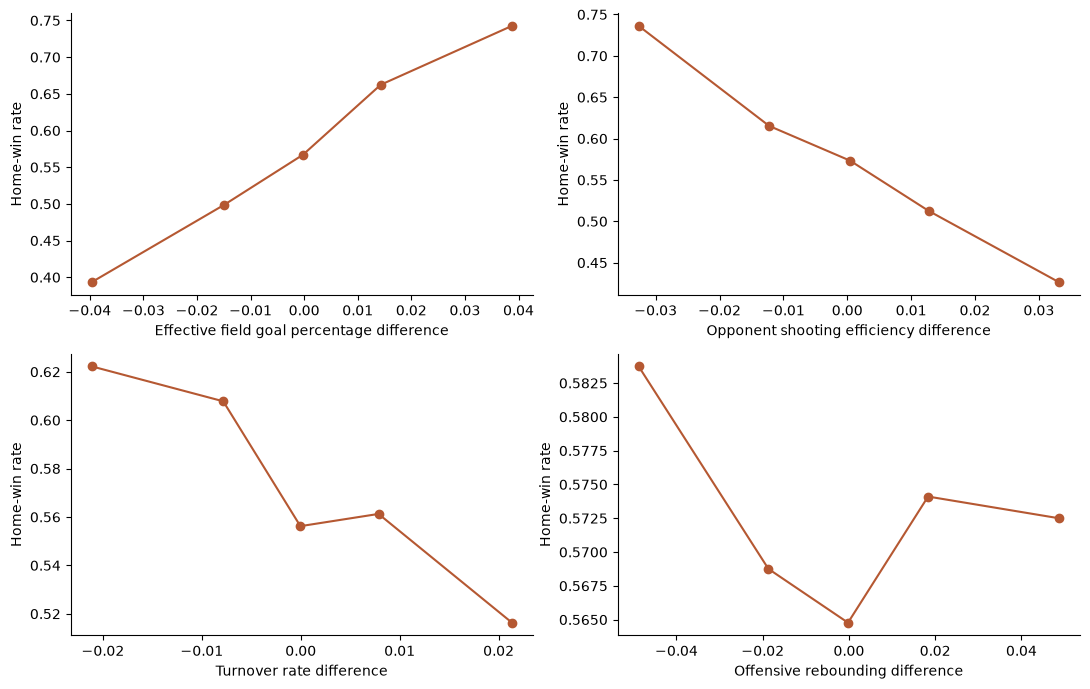

In [8]:
guide = pd.read_csv(TABLES / "feature_guide.csv")
focus = ["efg", "opp_efg", "tov_rate", "oreb_rate"]
display(
    guide[guide.metric.isin(focus)][["label", "question", "construction", "caution"]]
)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, metric in zip(axes.flat, focus):
    b = binned_outcomes(dev, metric + "_diff")
    ax.plot(b.value, b.home_win_rate, "o-", color=CLAY)
    ax.set(xlabel=feature_label(metric) + " difference", ylabel="Home-win rate")
finish(fig, "story_basketball_rates.png")

These plots are a reason to test a small basketball-motivated set, not to include every available statistic. I also consider defensive rebounding and free-throw rate. The feature notebook will show their denominators, including why the opponent row is necessary for defensive rebounds. Later I compare the whole team set against net rating alone and inspect regularized coefficients rather than treating these marginal slopes as independent effects.

## Can recent form add something beyond the season average?

A short window reacts quickly but can chase shooting noise. A long window is steadier but may miss a changing rotation. I look at five, ten and twenty games before choosing a window, then let chronological validation decide whether any of them belongs in the final team model.

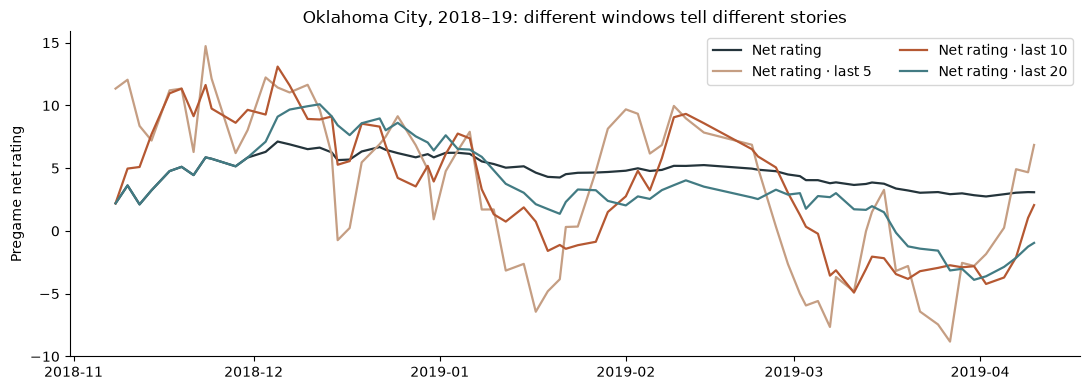

Standard deviation of game-to-game changes in this example:


,Change variability
net_rating,0.476
last5_net_rating,3.181
last10_net_rating,1.785
last20_net_rating,0.845


In [9]:
history = pd.read_csv(TABLES / "team_history.csv.gz", parse_dates=["gamedate"])
okc = history[
    (history.season == 2018) & history.off_team.eq("OKC") & history.prior_games.ge(10)
]
windows = ["net_rating", "last5_net_rating", "last10_net_rating", "last20_net_rating"]
fig, ax = plt.subplots(figsize=(11, 4))
for feature, color in zip(windows, ["#24343b", "#c59e83", CLAY, TEAL]):
    ax.plot(
        okc.gamedate,
        okc[feature],
        label=feature_label(feature),
        color=color,
        linewidth=1.6,
    )
ax.set(
    ylabel="Pregame net rating",
    title="Oklahoma City, 2018–19: different windows tell different stories",
)
ax.legend(ncol=2)
finish(fig, "story_recent_windows.png")
print("Standard deviation of game-to-game changes in this example:")
display(okc[windows].diff().std().rename("Change variability").to_frame().round(3))

,strength_band,recent_direction,home_win_rate,games
0,Away stronger,Recent form favors home less,0.362,1584
1,Away stronger,Recent form favors home more,0.390,1531
2,Similar strength,Recent form favors home less,0.561,1601
3,Similar strength,Recent form favors home more,0.607,1513
4,Home stronger,Recent form favors home less,0.740,1528
5,Home stronger,Recent form favors home more,0.778,1587


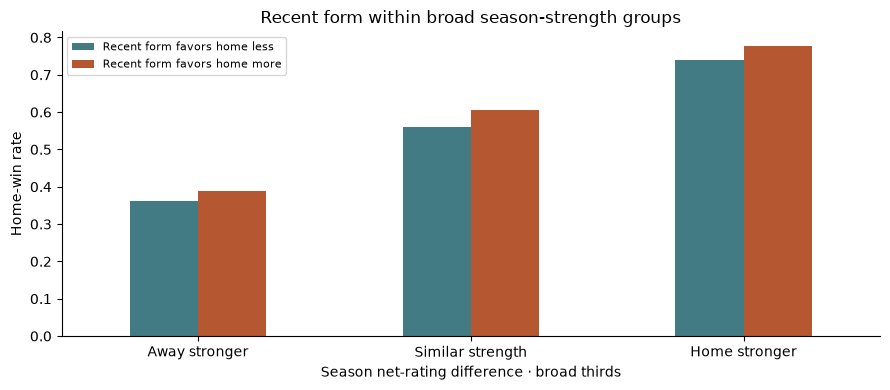

In [10]:
conditional = pd.read_csv(TABLES / "eda_recent_conditional.csv")
display(conditional.round(3))
fig, ax = plt.subplots()
conditional.pivot(
    index="strength_band", columns="recent_direction", values="home_win_rate"
).reindex(["Away stronger", "Similar strength", "Home stronger"]).plot.bar(
    ax=ax, color=[TEAL, CLAY], rot=0
)
ax.set(
    xlabel="Season net-rating difference · broad thirds",
    ylabel="Home-win rate",
    title="Recent form within broad season-strength groups",
)
ax.legend(fontsize=8)
finish(fig, "story_recent_conditional.png")

Within each broad strength group, games where the last ten games favor home more than the season average have a higher home-win rate. This is still only a coarse descriptive adjustment: the groups contain different teams and unequal exact strength. It motivates testing recent form, not announcing a separate “hot hand” effect. In notebook 3 the additional team windows yield only small validation gains once player histories are included.

## What if the record was built by a different rotation?

Team averages can lag changes in who is playing and who is scoring. The player file is useful only if I respect role: a regular playing thirty minutes should contribute more than a four-minute reserve. I begin with concentration and continuity before designing weighted recent performance and participation measures.

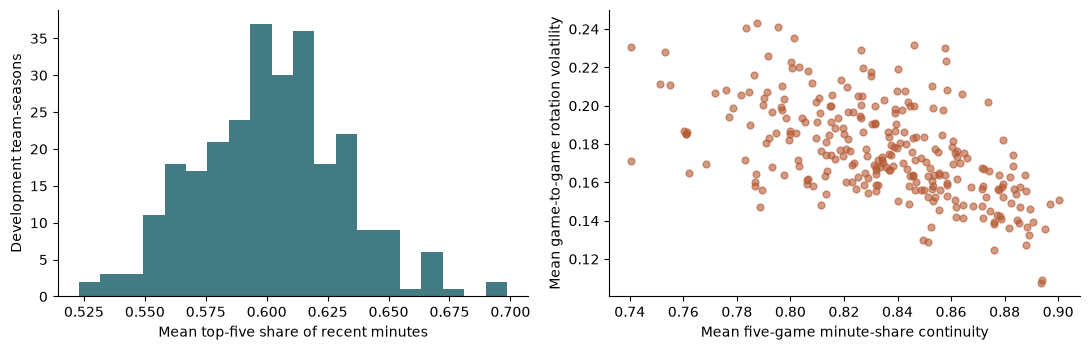

,player_name,role_minutes,role_weight,participation,ppa
0,Paul George,34.788,0.125,1.0,1.375
1,Russell Westbrook,34.024,0.123,1.0,0.864
2,Steven Adams,33.265,0.120,1.0,1.171
3,Jerami Grant,30.455,0.110,1.0,1.085
4,Dennis Schröder,29.659,0.107,1.0,1.101
5,Terrance Ferguson,22.171,0.080,1.0,1.316
6,Alex Abrines,19.080,0.069,1.0,0.533
7,Patrick Patterson,14.625,0.053,1.0,0.455


In [11]:
rotations = pd.read_csv(TABLES / "eda_rotations.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(rotations.top5_share, bins=20, color=TEAL)
axes[0].set(
    xlabel="Mean top-five share of recent minutes", ylabel="Development team-seasons"
)
axes[1].scatter(rotations.continuity, rotations.volatility, alpha=0.6, s=24, color=CLAY)
axes[1].set(
    xlabel="Mean five-game minute-share continuity",
    ylabel="Mean game-to-game rotation volatility",
)
finish(fig, "story_rotation_profiles.png")
roles = pd.read_csv(TABLES / "worked_player_roles.csv")
display(
    roles[["player_name", "role_minutes", "role_weight", "participation", "ppa"]]
    .head(8)
    .round(3)
)

The top five account for about 60% of recent minutes on average, with substantial variation between team-seasons. Continuity and volatility describe related but different timescales. The player table illustrates another distinction: a role estimate uses prior appearances, whereas participation asks how often the player has appeared recently. Averaging every rostered player equally would blur those roles.

**Candidate choice:** test normal-role-weighted scoring efficiency, participation and historical absences alongside concentration and continuity. Same-game `missed`, starter status and minutes are excluded because their pre-tipoff availability is not established.

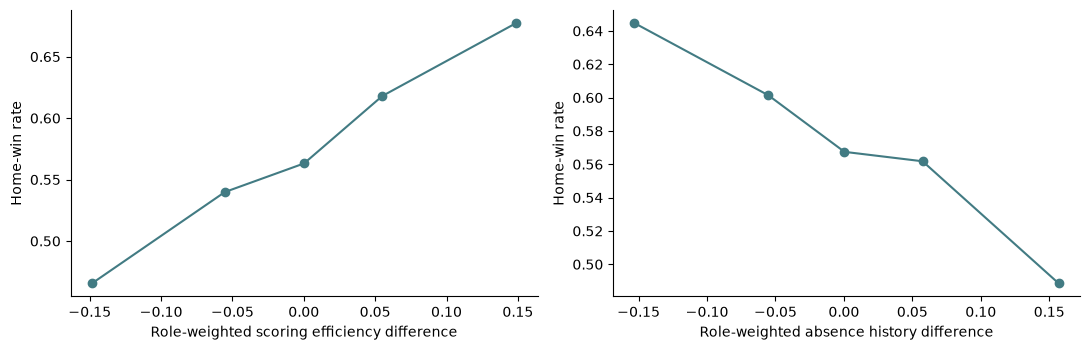

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, feature in zip(axes, ["weighted_ppa_diff", "weighted_absence_diff"]):
    b = binned_outcomes(dev, feature)
    ax.plot(b.value, b.home_win_rate, "o-", color=TEAL)
    ax.set(xlabel=feature_label(feature) + " difference", ylabel="Home-win rate")
finish(fig, "story_player_signals.png")

These are unadjusted player-history associations. They may reflect team quality as much as a distinct roster signal. The controlled development comparison will hold the model family and regularization setting fixed, then add player histories to the team inputs. That is a stronger test of usefulness than these curves alone.

## Is the schedule a missing piece of the matchup?

Dates let me distinguish a team playing on consecutive days from one with time off, without importing travel data. I check whether the descriptive differences are large enough to justify a few simple context inputs.

,schedule,home_win_rate,games,mean_strength_diff
0,Both on back-to-backs,0.613,475,-0.131
1,Neither on back-to-back,0.568,6285,-0.131
2,Only away on back-to-back,0.613,1758,-0.088
3,Only home on back-to-back,0.504,826,-0.042


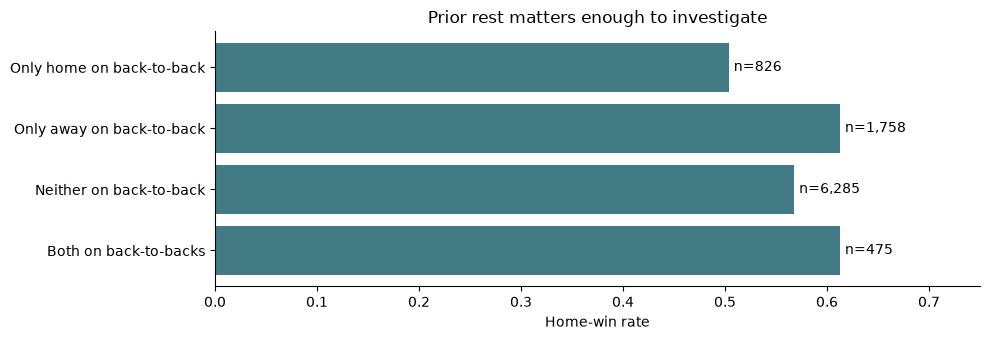

In [13]:
rest = pd.read_csv(TABLES / "eda_rest.csv")
display(rest.round(3))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.barh(rest.schedule, rest.home_win_rate, color=TEAL)
ax.set(
    xlabel="Home-win rate",
    title="Prior rest matters enough to investigate",
    xlim=(0, 0.75),
)
for i, row in rest.iterrows():
    ax.text(row.home_win_rate + 0.005, i, f"n={row.games:,}", va="center")
finish(fig, "story_rest.png")

Home teams on the only back-to-back win about 50.4% of these games; home teams whose opponent alone is on a back-to-back win about 61.3%. Those are associations, not a clean experiment in fatigue. I include rest, a back-to-back indicator and recent game count, while acknowledging missing travel and neutral-site information.

## Which ideas are telling us the same thing?

Adding related inputs is not automatically adding independent information. Before fitting, I check redundancy among record, scoring margin, recent strength and player concentration.

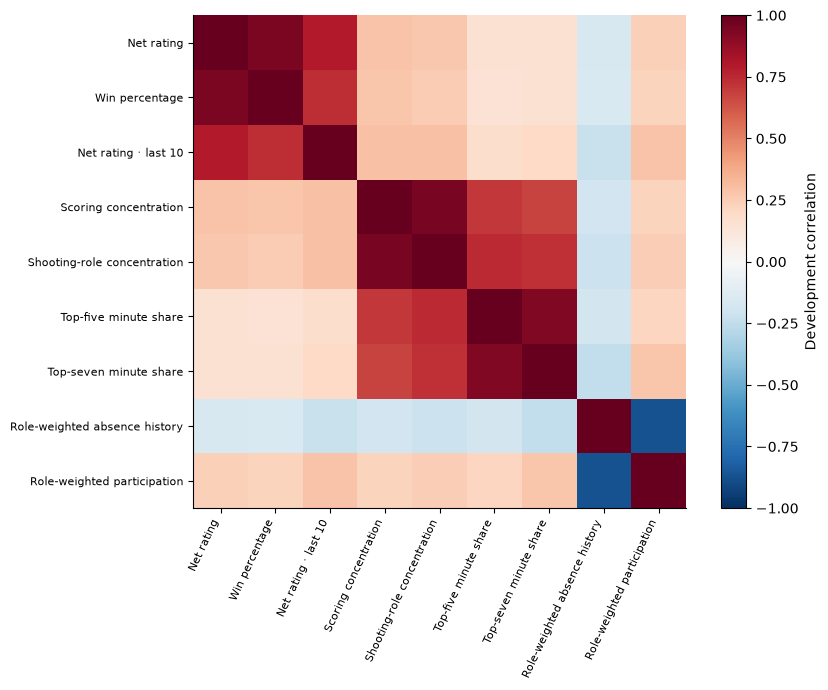

,feature_a,feature_b,correlation
0,scoring_concentration_diff,usage_concentration_diff,0.947
1,net_rating_diff,win_pct_diff,0.939
2,top5_share_diff,top7_share_diff,0.926
3,weighted_absence_diff,weighted_participation_diff,-0.874
4,net_rating_diff,last10_net_rating_diff,0.794
5,efg_diff,last10_efg_diff,0.756


In [14]:
columns = [
    "net_rating_diff",
    "win_pct_diff",
    "last10_net_rating_diff",
    "scoring_concentration_diff",
    "usage_concentration_diff",
    "top5_share_diff",
    "top7_share_diff",
    "weighted_absence_diff",
    "weighted_participation_diff",
]
corr = dev[columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(
    range(len(columns)),
    [feature_label(c) for c in columns],
    rotation=65,
    ha="right",
    fontsize=8,
)
ax.set_yticks(range(len(columns)), [feature_label(c) for c in columns], fontsize=8)
fig.colorbar(im, ax=ax, label="Development correlation")
finish(fig, "story_correlations.png")
display(pd.read_csv(TABLES / "feature_correlations.csv").head(6).round(3))

Net rating/record correlate at 0.939, scoring/usage concentration at 0.947, and top-five/top-seven minute shares at 0.926. This leads to regularization and feature-set comparisons, rather than a claim that each variable measures a separate effect. Coefficient stability will matter as much as a large coefficient in one fit.

## From observations to a deliberate candidate set

| Observation | Basketball hypothesis | What I will construct | What could go wrong? |
|---|---|---|---|
| Better records and margins track wins | Season strength should be a strong starting point | Pregame win percentage and net rating | Noisy early records; overlapping information |
| Teams create points in different ways | Shooting and possession control may add detail | A small set of correctly defined rates | Correlated summaries of the same strength |
| Recent windows depart from season strength | Changes may matter before the season average catches up | 5/10/20-game net rating and shooting | Small samples and redundant windows |
| Roles and participation vary | Established players' recent form may help | Prior-role-weighted performance and participation | Stale rosters; no current injury timestamps |
| Back-to-back groups differ | Rest could add game context | Prior rest and schedule density | No travel or neutral-site adjustment |

These are reasons to **test** the features, not reasons to guarantee their inclusion. [Next: reconstruct one game before tipoff](02_pregame_features.ipynb).